In [10]:
%matplotlib inline
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

from clean_mission1 import DATA_DIR, OUT_DIR, load_cleaned

print('Python', sys.version.split()[0], sys.executable)
print('Using existing cleaned data in', OUT_DIR)

Python 3.13.3 c:\Users\Kinga\AppData\Local\Programs\Python\Python313\python.exe
Using existing cleaned data in c:\Users\Kinga\OneDrive\Desktop\spacecraft-anomaly-prediction\cleaned\mission1_30s


In [11]:
meta = json.load(open(f'{OUT_DIR}/meta.json'))
nan = pd.Series({k: v['nan_frac'] for k, v in meta['channels'].items()})
hold = pd.Series({k: v['hold_seconds'] for k, v in meta['channels'].items()})
print(f"{meta['n_channels']} channels, {meta['n_timestamps']:,} timestamps at {meta['freq']}")
print(f"NaN fraction  min {nan.min():.3%}  median {nan.median():.3%}  max {nan.max():.3%}")
print(f"Hold (s)      min {hold.min():.0f}  median {hold.median():.0f}  max {hold.max():.0f}")
nan.sort_values(ascending=False).head(8)

76 channels, 14,728,320 timestamps at 30s
NaN fraction  min 0.005%  median 0.016%  max 0.702%
Hold (s)      min 600  median 600  max 2700


channel_61    0.007020
channel_62    0.007020
channel_63    0.007020
channel_75    0.004379
channel_76    0.004379
channel_71    0.004379
channel_73    0.004379
channel_72    0.004378
dtype: float64

Loading raw and cleaned windows...
raw 271 points, cleaned 810 points


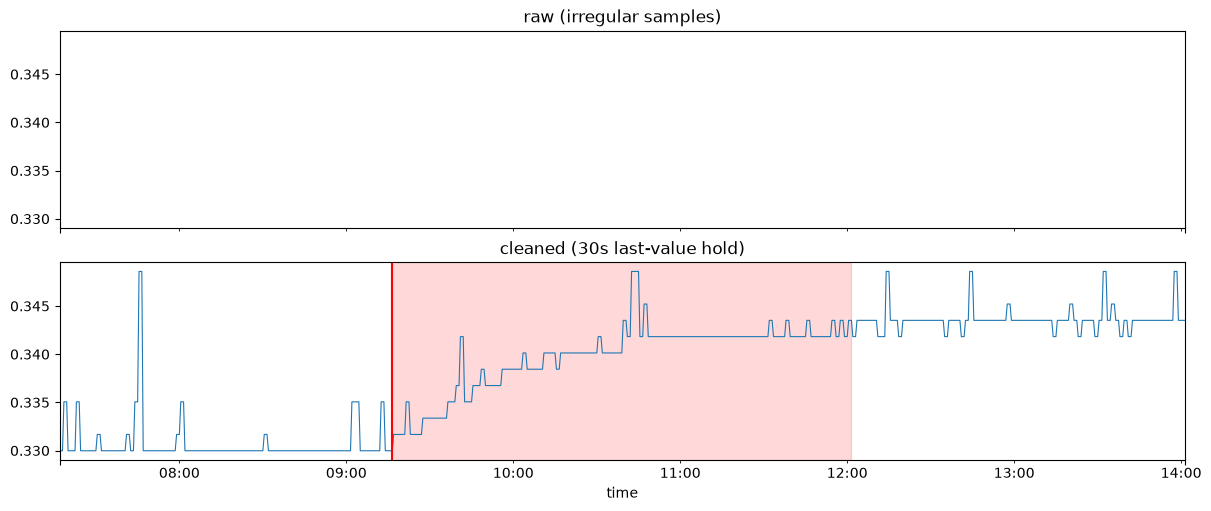

In [ ]:
# Raw vs cleaned around a known anomaly. The red band is the labeled period.
labels = pd.read_csv(f'{DATA_DIR}/labels.csv', parse_dates=['StartTime', 'EndTime'])
row = labels[(labels.ID == 'id_137') & (labels.Channel == 'channel_14')].iloc[0]
start, end = row.StartTime.tz_localize(None), row.EndTime.tz_localize(None)
window = (start - pd.Timedelta(hours=2), end + pd.Timedelta(hours=2))

print('Loading raw and cleaned windows...')
raw = pd.read_pickle(f'{DATA_DIR}/channels/channel_14.zip')['channel_14'].loc[window[0]:window[1]]
clean = load_cleaned(*window, channels=['channel_14'])['channel_14']
print(f'raw {len(raw)} points, cleaned {len(clean)} points')

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, layout='constrained')
raw.plot(ax=axes[0], lw=0.8, title='raw (irregular samples)')
clean.plot(ax=axes[1], lw=0.8, title='cleaned (30s last-value hold)')
for ax in axes:
    ax.axvspan(start, end, color='red', alpha=0.15)
    ax.axvline(start, color='red')
plt.show()